# Exercise 6: Training a CNN on CIFAR-10

This notebook starts with the code of the official PyTorch tutorial
[Training a Classifier](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html):
loading CIFAR-10, the network from the slides and the training loop.

**Task 1** is to get this running on your own computer. The **follow-up tasks** each ask you to change either the network or the training loop. You don't have to do all of them; pick the ones that interest you, but do Task 2 first, since the others need it.

Note: Every task from **Task 4** onward is considered as a bonus task. 

There are no asserts in this notebook. Each task has a **checkpoint** that tells you roughly what you should see. If your result is far off, compare with your neighbours.

Everything runs on a CPU. A GPU (or an Apple M-chip) makes it faster, see the bonus task at the end. Training the bigger networks takes several minutes: start a run and read the next task while it trains.

---
# Starter code (from the PyTorch tutorial)

## 1. Load and normalize CIFAR-10

The first run downloads the dataset (about 170 MB) into the folder `./data`.

**Note from the tutorial:** If you are running this on Windows or macOS and get a `BrokenPipeError` or a `RuntimeError` related to multiprocessing, set `num_workers=0` in the two `DataLoader`s.

In [6]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


Let us show some of the training images:

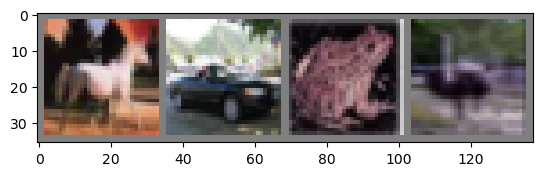

horse car   frog  bird 


In [7]:
import matplotlib.pyplot as plt
import numpy as np


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

## 2. Define a convolutional neural network

In [8]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

## 3. Define a loss function and optimizer

In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

## 4. Train the network

In [10]:
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

[1,  2000] loss: 2.226
[1,  4000] loss: 1.805
[1,  6000] loss: 1.638
[1,  8000] loss: 1.571
[1, 10000] loss: 1.504
[1, 12000] loss: 1.450
[2,  2000] loss: 1.393
[2,  4000] loss: 1.380
[2,  6000] loss: 1.358
[2,  8000] loss: 1.335
[2, 10000] loss: 1.310
[2, 12000] loss: 1.300
Finished Training


---
# Task 1: Train the network on your computer

Run all cells above.

* How long does the training take on your computer? Measure it: put `start = time.time()` before the training loop and print `time.time() - start` after it (`import time` first).
* What is the loss of a network that guesses randomly among 10 classes? (Hint: cross-entropy of a uniform guess is −ln(1/10).) Is your network better?

**Checkpoint:** the loss starts around 2.3 and goes down clearly during the two epochs. On a laptop CPU the two epochs take a few minutes.

In [11]:
import time

net = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

start = time.time()
for epoch in range(2):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if i % 2000 == 1999:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
print(f'Finished Training in {time.time() - start:.0f} s')

# random guessing: -ln(1/10) = 2.30

[1,  2000] loss: 2.230
[1,  4000] loss: 1.886
[1,  6000] loss: 1.694
[1,  8000] loss: 1.595
[1, 10000] loss: 1.521
[1, 12000] loss: 1.448
[2,  2000] loss: 1.405
[2,  4000] loss: 1.362
[2,  6000] loss: 1.356
[2,  8000] loss: 1.331
[2, 10000] loss: 1.295
[2, 12000] loss: 1.275
Finished Training in 112 s


# Task 2: How good is the network?

The training loss alone doesn't tell you how well the network classifies **new** images.

a) Write a function `evaluate(net, loader)` that returns the accuracy (fraction of correctly classified images) of `net` on all images of `loader`. Use it to compute the test accuracy of your trained network.

Hints: `torch.no_grad()` switches off gradient computation; the predicted class is the index of the largest output (`outputs.argmax(dim=1)`).

b) Which class does the network recognize best, which one worst? Compute the accuracy per class.

**Checkpoint:** clearly above 10% (random guessing); the PyTorch tutorial reports around 50% after 2 epochs.

In [12]:
def evaluate(net, loader):
    net.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            predicted = net(images).argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    net.train()
    return correct / total


print(f'Test accuracy: {evaluate(net, testloader):.1%}')

Test accuracy: 54.4%


In [13]:
correct_pred = {c: 0 for c in classes}
total_pred = {c: 0 for c in classes}
with torch.no_grad():
    for images, labels in testloader:
        predictions = net(images).argmax(dim=1)
        for label, prediction in zip(labels, predictions):
            correct_pred[classes[label]] += int(label == prediction)
            total_pred[classes[label]] += 1

for c in classes:
    print(f'{c:5s}: {correct_pred[c] / total_pred[c]:.1%}')

plane: 56.6%
car  : 57.3%
bird : 35.4%
cat  : 14.1%
deer : 37.7%
dog  : 56.3%
frog : 75.7%
horse: 71.2%
ship : 76.4%
truck: 63.5%


# Task 3: Larger batches

The tutorial uses `batch_size = 4`, so one epoch has 12,500 weight updates.

a) Change the batch size to 64 (you have to recreate the `DataLoader`s) and train a new network for 2 epochs. Compare training time and test accuracy with Task 1/2.

b) Your accuracy probably got worse. Try to fix it without going back to small batches, for example with a larger learning rate or more epochs.

**Checkpoint:** an epoch with batch size 64 is several times faster. With the same learning rate (0.001) the accuracy after 2 epochs drops clearly, because the network makes 16× fewer updates. A learning rate of about 0.01 brings it back.

In [14]:
def make_loaders(batch_size):
    trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
    testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=2)
    return trainloader, testloader


def train(net, trainloader, epochs=2, lr=0.001, optimizer=None):
    criterion = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    start = time.time()
    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in trainloader:
            optimizer.zero_grad()
            loss = criterion(net(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f'epoch {epoch + 1}: loss {running_loss / len(trainloader):.3f}')
    return time.time() - start


trainloader64, testloader64 = make_loaders(64)

net = Net()
seconds = train(net, trainloader64, epochs=2, lr=0.001)
print(f'batch 64, lr 0.001: {seconds:.0f} s, test accuracy {evaluate(net, testloader64):.1%}')

epoch 1: loss 2.300
epoch 2: loss 2.163
batch 64, lr 0.001: 65 s, test accuracy 28.3%


In [15]:
net = Net()
seconds = train(net, trainloader64, epochs=2, lr=0.01)
print(f'batch 64, lr 0.01: {seconds:.0f} s, test accuracy {evaluate(net, testloader64):.1%}')

epoch 1: loss 1.795
epoch 2: loss 1.394
batch 64, lr 0.01: 58 s, test accuracy 53.1%


# Task 4: Watch the training: learning curves and overfitting

So far we only know the accuracy at the very end. Change the training so that you can see how the network develops.

a) Split 5,000 images off the training set as a **validation set** (`torch.utils.data.random_split`). From now on, compare models on the validation set; the test set is only for the very end.

b) Change the training loop so that it records the average training loss and the validation accuracy **after every epoch**. Train for 10 epochs and plot both curves. (With batch size 64 and the small network this takes a few minutes.)

c) Also record the training accuracy. Do training and validation accuracy drift apart? From which epoch on would you stop training?

**Checkpoint:** the validation accuracy rises quickly in the first epochs and then flattens out, while the training accuracy keeps rising. The growing gap is overfitting.

epoch 1: loss 1.865  train acc 31.5%  val acc 43.2%
epoch 2: loss 1.427  train acc 48.1%  val acc 52.4%
epoch 3: loss 1.276  train acc 54.2%  val acc 54.1%
epoch 4: loss 1.176  train acc 58.3%  val acc 58.0%
epoch 5: loss 1.100  train acc 60.7%  val acc 57.1%
epoch 6: loss 1.041  train acc 63.3%  val acc 60.0%
epoch 7: loss 0.986  train acc 65.0%  val acc 61.0%
epoch 8: loss 0.936  train acc 66.8%  val acc 62.6%
epoch 9: loss 0.893  train acc 68.5%  val acc 61.6%
epoch 10: loss 0.854  train acc 69.8%  val acc 59.6%


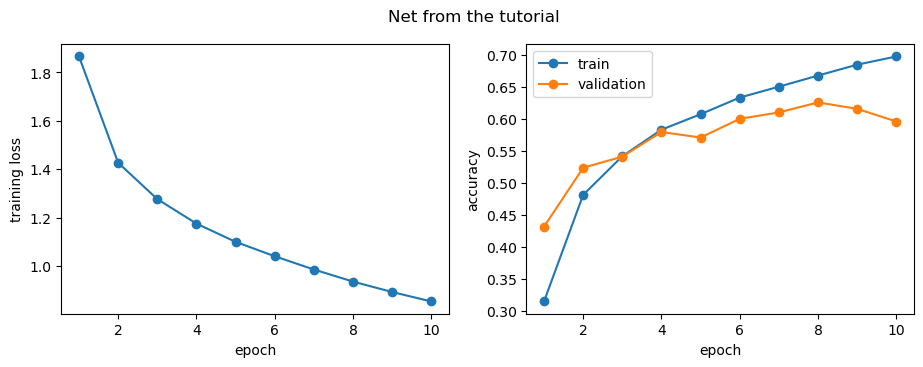

In [16]:
train_subset, val_subset = torch.utils.data.random_split(
    trainset, [len(trainset) - 5000, 5000], generator=torch.Generator().manual_seed(0))

trainloader = torch.utils.data.DataLoader(train_subset, batch_size=64, shuffle=True, num_workers=2)
valloader = torch.utils.data.DataLoader(val_subset, batch_size=256, shuffle=False, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=2)


def train_with_history(net, epochs=10, lr=0.01, optimizer=None):
    criterion = nn.CrossEntropyLoss()
    if optimizer is None:
        optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    history = {'loss': [], 'train_acc': [], 'val_acc': []}
    start = time.time()
    for epoch in range(epochs):
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
        history['loss'].append(running_loss / total)
        history['train_acc'].append(correct / total)
        history['val_acc'].append(evaluate(net, valloader))
        print(f"epoch {epoch + 1}: loss {history['loss'][-1]:.3f}  "
              f"train acc {history['train_acc'][-1]:.1%}  val acc {history['val_acc'][-1]:.1%}")
    history['seconds'] = time.time() - start
    return history


def plot_history(history, title=''):
    epochs = range(1, len(history['loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(epochs, history['loss'], marker='o')
    ax1.set_xlabel('epoch'); ax1.set_ylabel('training loss')
    ax2.plot(epochs, history['train_acc'], marker='o', label='train')
    ax2.plot(epochs, history['val_acc'], marker='o', label='validation')
    ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy'); ax2.legend()
    fig.suptitle(title)
    plt.show()


net = Net()
history_base = train_with_history(net, epochs=10)
plot_history(history_base, 'Net from the tutorial')

# Task 5: A wider network

The network from the tutorial has only 6 and 16 filters.

a) Increase the number of filters to 32 in `conv1` and 64 in `conv2`. Which other layer do you have to change, and why? Train it like in Task 4, but for 5 epochs to save time.

b) Compare with the original network: validation accuracy, number of parameters (`sum(p.numel() for p in net.parameters())`) and training time. Where did the additional parameters end up?

**Checkpoint:** the wider network reaches a clearly higher validation accuracy, but each epoch takes noticeably longer. Most of the additional parameters sit in `fc1`.

conv1     2,432
pool          0
conv2    51,264
fc1     192,120
fc2      10,164
fc3         850
epoch 1: loss 1.735  train acc 35.7%  val acc 48.6%
epoch 2: loss 1.236  train acc 55.3%  val acc 60.0%
epoch 3: loss 1.035  train acc 63.2%  val acc 62.0%
epoch 4: loss 0.881  train acc 68.8%  val acc 67.0%
epoch 5: loss 0.768  train acc 73.2%  val acc 67.4%


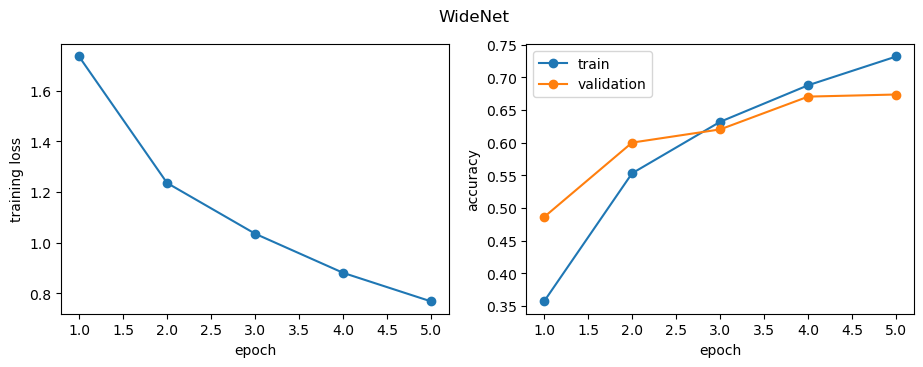

Net:        62,006 parameters, best val acc 62.6%, 474 s
WideNet:   256,830 parameters, best val acc 67.4%, 305 s


In [17]:
class WideNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 5)
        self.fc1 = nn.Linear(64 * 5 * 5, 120)   # depth of the last feature map changed
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


def count_params(net):
    return sum(p.numel() for p in net.parameters())


for name, layer in WideNet().named_children():
    print(f'{name:6s} {count_params(layer):>8,}')

net = WideNet()
history_wide = train_with_history(net, epochs=5)
plot_history(history_wide, 'WideNet')
print(f'Net:     {count_params(Net()):>9,} parameters, best val acc {max(history_base["val_acc"]):.1%}, {history_base["seconds"]:.0f} s')
print(f'WideNet: {count_params(WideNet()):>9,} parameters, best val acc {max(history_wide["val_acc"]):.1%}, {history_wide["seconds"]:.0f} s')

# Task 6: A deeper network with 3×3 filters

Modern CNNs use small 3×3 filters with padding and stack more conv layers.

Build a network with **four** conv layers with 3×3 filters and `padding=1`, and a max pooling layer after every second conv layer, for example with 16, 16, 32, 32 filters. (More filters work better, but training gets slow on a CPU.) Compute the input size of the first fully connected layer **on paper first** (like on the exercise sheet), then check it by running the network.

Train it for 5 epochs and compare with Task 5.

**Checkpoint:** after the two poolings the feature maps are 8×8, so `fc1` gets 32·8·8 = 2048 inputs. The deeper network should beat the original network on the validation set.

epoch 1: loss 1.901  train acc 29.6%  val acc 43.8%
epoch 2: loss 1.332  train acc 51.9%  val acc 58.3%
epoch 3: loss 1.067  train acc 61.8%  val acc 63.3%
epoch 4: loss 0.891  train acc 68.2%  val acc 68.2%
epoch 5: loss 0.765  train acc 72.8%  val acc 68.8%


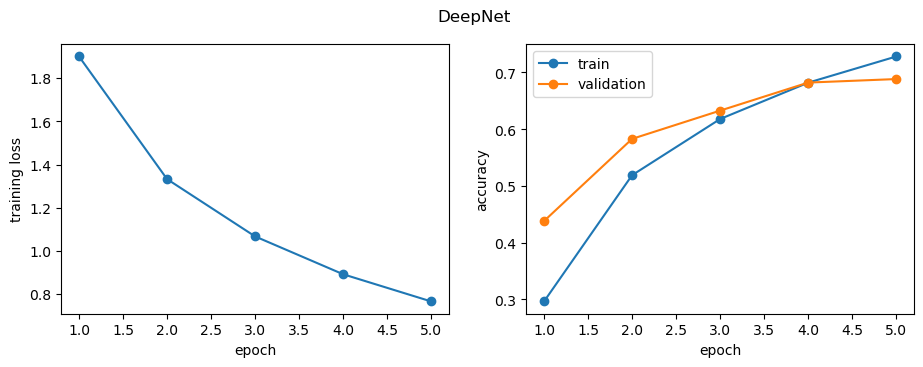

DeepNet:   280,218 parameters, best val acc 68.8%, 357 s


In [18]:
class DeepNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)   # 32 -> 16 -> 8
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))
        x = F.relu(self.conv3(x))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


net = DeepNet()
history_deep = train_with_history(net, epochs=5)
plot_history(history_deep, 'DeepNet')
print(f'DeepNet: {count_params(net):>9,} parameters, best val acc {max(history_deep["val_acc"]):.1%}, {history_deep["seconds"]:.0f} s')

# Task 7: A different optimizer

Replace SGD in your training loop by the Adam optimizer (`optim.Adam`, learning rate 0.001) and train one of your networks again. Does it learn faster in the first epochs? Is the final validation accuracy better?

**Checkpoint:** Adam usually reaches a good accuracy in fewer epochs than SGD with these settings; the final accuracy is similar.

epoch 1: loss 1.518  train acc 44.9%  val acc 54.2%
epoch 2: loss 1.133  train acc 59.4%  val acc 61.4%
epoch 3: loss 0.945  train acc 66.6%  val acc 65.7%
epoch 4: loss 0.817  train acc 71.3%  val acc 68.9%
epoch 5: loss 0.722  train acc 74.6%  val acc 68.7%


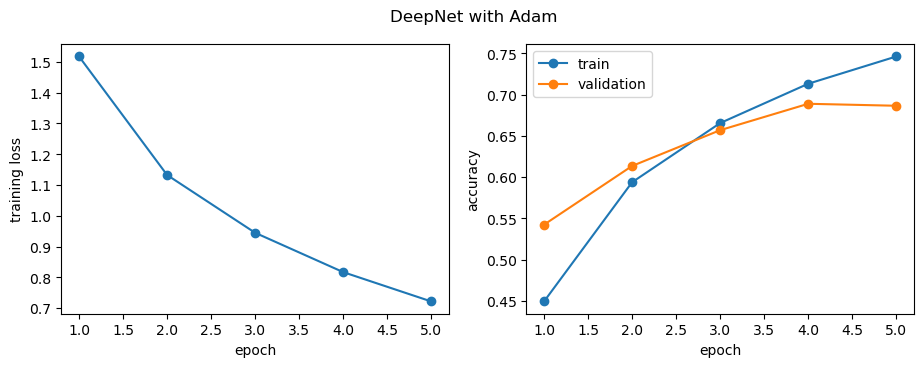

In [19]:
net = DeepNet()
history_adam = train_with_history(net, epochs=5, optimizer=optim.Adam(net.parameters(), lr=0.001))
plot_history(history_adam, 'DeepNet with Adam')

# Task 8: Fighting overfitting

Your bigger networks overfit after a few epochs. Try one or more of the following (all not on the slides, look them up in the PyTorch documentation) and see whether the gap between training and validation accuracy gets smaller:

* **Data augmentation:** use a separate transform for the training set with `v2.RandomHorizontalFlip()` and `v2.RandomCrop(32, padding=4)`. The validation and test sets keep the original transform. Careful: with `random_split` both subsets share the transform of `trainset`, so you need a second `CIFAR10` object for the training data.
* **Dropout:** `nn.Dropout(0.5)` before the fully connected layers.
* **Batch normalization:** `nn.BatchNorm2d` after each conv layer.

**Checkpoint:** with data augmentation the training accuracy stays much closer to the validation accuracy, and the validation accuracy keeps rising for more epochs.

Files already downloaded and verified
epoch 1: loss 1.732  train acc 36.5%  val acc 47.0%
epoch 2: loss 1.412  train acc 48.8%  val acc 54.3%
epoch 3: loss 1.243  train acc 55.2%  val acc 60.0%
epoch 4: loss 1.105  train acc 60.4%  val acc 65.8%
epoch 5: loss 1.018  train acc 63.8%  val acc 68.4%
epoch 6: loss 0.959  train acc 65.9%  val acc 69.2%
epoch 7: loss 0.905  train acc 67.7%  val acc 69.6%
epoch 8: loss 0.867  train acc 69.2%  val acc 71.5%
epoch 9: loss 0.838  train acc 70.3%  val acc 74.3%
epoch 10: loss 0.809  train acc 71.6%  val acc 72.1%


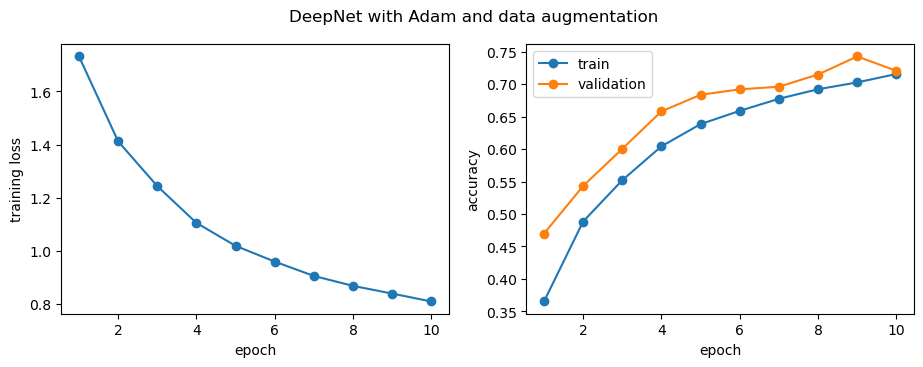

In [21]:
train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomHorizontalFlip(),
    v2.RandomCrop(32, padding=4),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

trainset_aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
train_idx = train_subset.indices    # same split as in Task 4
trainloader = torch.utils.data.DataLoader(torch.utils.data.Subset(trainset_aug, train_idx),
                                          batch_size=64, shuffle=True, num_workers=2)

net = DeepNet()
history_aug = train_with_history(net, epochs=10, optimizer=optim.Adam(net.parameters(), lr=0.001))
plot_history(history_aug, 'DeepNet with Adam and data augmentation')

# Task 9: Training on a GPU

If your computer has an NVIDIA GPU or an Apple M-chip, you can train on it. Change your training loop as in the
[GPU section of the tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html#training-on-gpu):

```python
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
net.to(device)
inputs, labels = inputs.to(device), labels.to(device)   # inside the loop
```

Compare the time per epoch for the small `Net` and for your largest network. For which one is the speed-up bigger, and why?

---
# Final step: your best model on the test set

Take the model with the best **validation** accuracy and evaluate it **once** on the test set. Write down your result and compare with your neighbours:

* Which change brought the largest improvement?
* Which change cost the most training time?
* Is your test accuracy close to the validation accuracy?

In [22]:
print(f'Test accuracy of the best model: {evaluate(net, testloader):.1%}')

Test accuracy of the best model: 73.0%
